# Práctica 3 - Visión por Computador

## Marcial Galván - Alejandra Rodríguez

### Tabla de contenidos

- [Tarea 1: Contador de monedas](#tarea-1-contador-de-monedas)
    - [1.1. Planteamiento](#11-planteamiento)
    - [1.2. Preparación](#12-preparación)
    - [1.3. Detección de círculos](#13-detección-de-círculos)
    - [1.4. Clasificación por color](#14-clasificación-por-color)
    - [1.5. Clasificación por tamaño](#15-clasificación-por-tamaño)
    - [1.6. Demostrador en vivo](#16-demostrador-en-vivo)
- [Tarea 2: Clasificación de microplásticos](#tarea-2-clasificación-de-microplásticos)
    - [2.1. Planteamiento](#21-planteamiento)
    - [2.2. Configuración](#22-configuración)
    - [2.3. Segmentación](#23-segmentación)
    - [2.4. Características](#24-características)
    - [2.5. _Data augmentation_](#25-data-augmentation)
    - [2.6. Clasificador por reglas heurísticas](#26-clasificador-por-reglas-heurísticas)
    - [2.7. Entrenamiento](#27-entrenamiento)
    - [2.8. Evaluación en la imagen de test](#28-evaluación-en-la-imagen-de-test)
    - [2.9. Comparación con otros clasificadores](#29-comparación-con-otros-clasificadores)

## Tarea 1: Contador de monedas

Realizar un demostrador que permita contar el dinero presente en una imagen en vivo, sin usar aprendizaje profundo.

### 1.1. Planteamiento

El _pipeline_ sigue estos pasos:

1. **Detección de círculos** con la transformada de Hough sobre la imagen preprocesada, descartando círculos demasiado grandes y duplicados.
2. **Color de cada moneda** en el espacio Lab, para distinguir los cuatro metales: cobre, oro, 1€ y 2€.
3. **Calibración píxeles/mm:** se elige la escala que mejor se adapta a los tamaños de todas las monedas.
4. **Clasificación** de cada moneda por su metal y su diámetro en mm.
5. **Demostrador en vivo:** pasos 1-4 fotograma a fotograma, con una estabilización de los resultados entre fotogramas.

Las decisiones del _pipeline_ se justifican en [`ablations_coins.ipynb`](./ablations_coins.ipynb).

### 1.2. Preparación

In [47]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt

En primer lugar, se establecen los datos de referencia de cada moneda de euro: nombre, valor, diámetro en mm y metal. El color de cada moneda se usa para dibujar su círculo en el demostrador en vivo.

In [48]:
COINS = {
    "name":        np.array(["1cent", "2cent", "5cent", "10cent", "20cent", "50cent", "1eur", "2eur"]),
    "value":       np.array([0.01, 0.02, 0.05, 0.10, 0.20, 0.50, 1.00, 2.00]),
    "diameter_mm": np.array([16.25, 18.75, 21.25, 19.75, 22.25, 24.25, 23.25, 25.75]),
    "metal":       np.array(["bronze", "bronze", "bronze", "gold", "gold", "gold", "1eur", "2eur"]),
    "color":       np.array([[0, 0, 255],
                             [0, 165, 255],
                             [0, 255, 255],
                             [0, 255, 191],
                             [0, 160, 0],
                             [255, 255, 0],
                             [255, 117, 44],
                             [240, 32, 160]]),
}

METAL = COINS["metal"]
COIN_DIAMETERS_MM = COINS["diameter_mm"]

También se definen algunas funciones auxiliares, que simplifican la implementación, posteriormente, de las distintas etapas del _pipeline_:

In [49]:
def to_gray(image):
    return cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

In [50]:
def show(images: list, size=(15, 5)):
    plt.figure(figsize=size)
    for i in range(len(images)):
        plt.subplot(1,len(images),i+1)
        plt.imshow(images[i], cmap='gray')
        plt.axis('off')
    plt.show()  

In [51]:
def put_text(img, text, org, scale=0.6):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), 4, cv2.LINE_AA)

Además, y antes de realizar el demostrador en vivo, se comprueba el funcionamiento de cada etapa del _pipeline_ sobre tres imágenes de ejemplo: `monedas1.jpg`, `monedas2.jpg` y `monedas3.webp`:

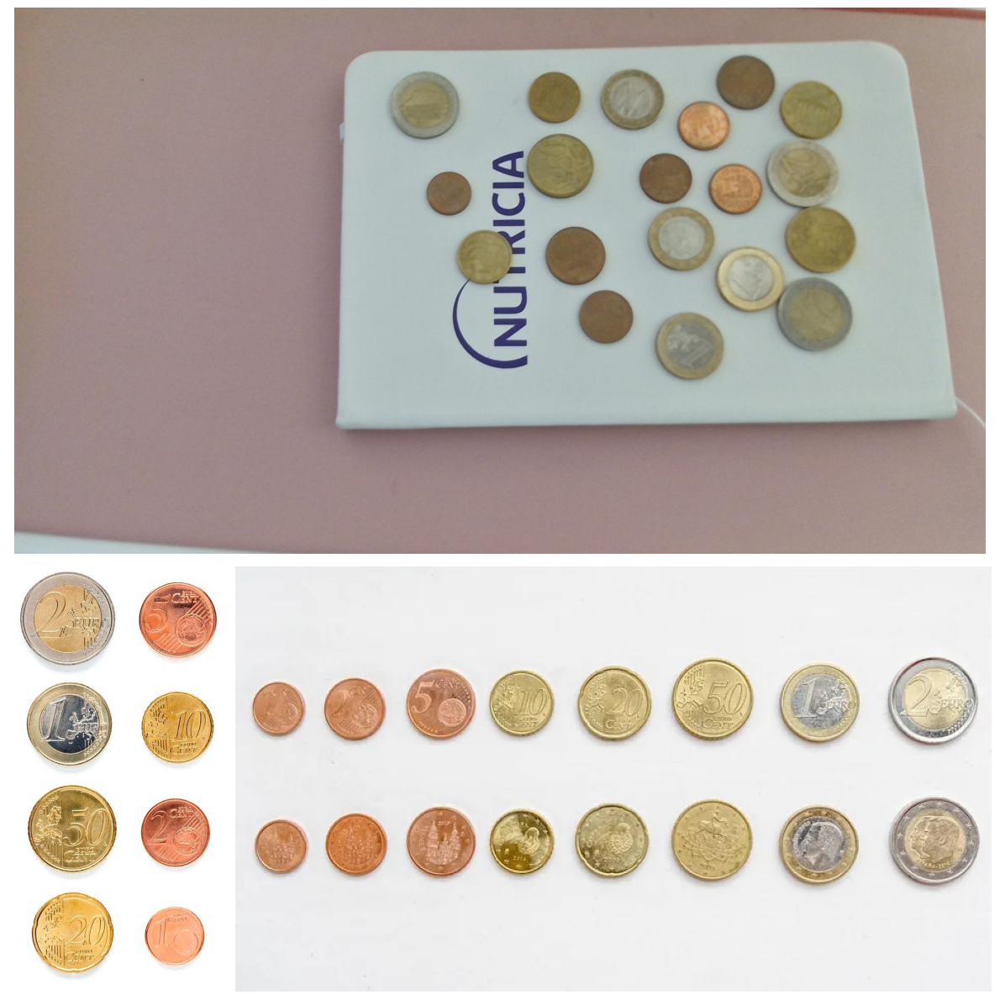

In [52]:
IMAGES = ["./exercises/coins/monedas1.jpg", "./exercises/coins/monedas2.jpg", "./exercises/coins/monedas3.webp"]
images = [cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB) for path in IMAGES]

def show_each(images, width=12):
    top, bottom = images[0], images[1:]
    ratios = [img.shape[1] / img.shape[0] for img in bottom]
    heights = [top.shape[0] / top.shape[1], 1 / sum(ratios)]

    fig = plt.figure(figsize=(width, width * sum(heights)))
    grid = fig.add_gridspec(2, len(bottom), width_ratios=ratios, height_ratios=heights)
    axes = [fig.add_subplot(grid[0, :])] + [fig.add_subplot(grid[1, i]) for i in range(len(bottom))]
    for ax, img in zip(axes, images):
        ax.imshow(img, cmap="gray")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_each(images)

### 1.3. Detección de círculos

Antes de realizar la detección, se realiza una corrección gamma sobre la imagen. Con una gamma menor que 1 se oscurecen los tonos más oscuros, y se aumenta el contraste entre los tonos claros, lo que permite diferenciar mejor las monedas:

In [53]:
def gammaCorrection(src, gamma):
    invGamma = 1 / gamma

    table = [((i / 255) ** invGamma) * 255 for i in range(256)]
    table = np.array(table, np.uint8)

    return cv2.LUT(src, table)

Antes de pasar a Hough, también se realiza un preprocesado de la imagen corregida con gamma, utilizando un filtro bilateral y la conversión a escala de grises:

In [54]:
def pre_hough_transforms(image):
    return to_gray(gammaCorrection(cv2.bilateralFilter(image, 21, 75, 999), 0.4))

Resultado del preprocesado sobre las imágenes de prueba. El dibujo interior de las monedas se suaviza y sus bordes destacan más sobre el fondo:

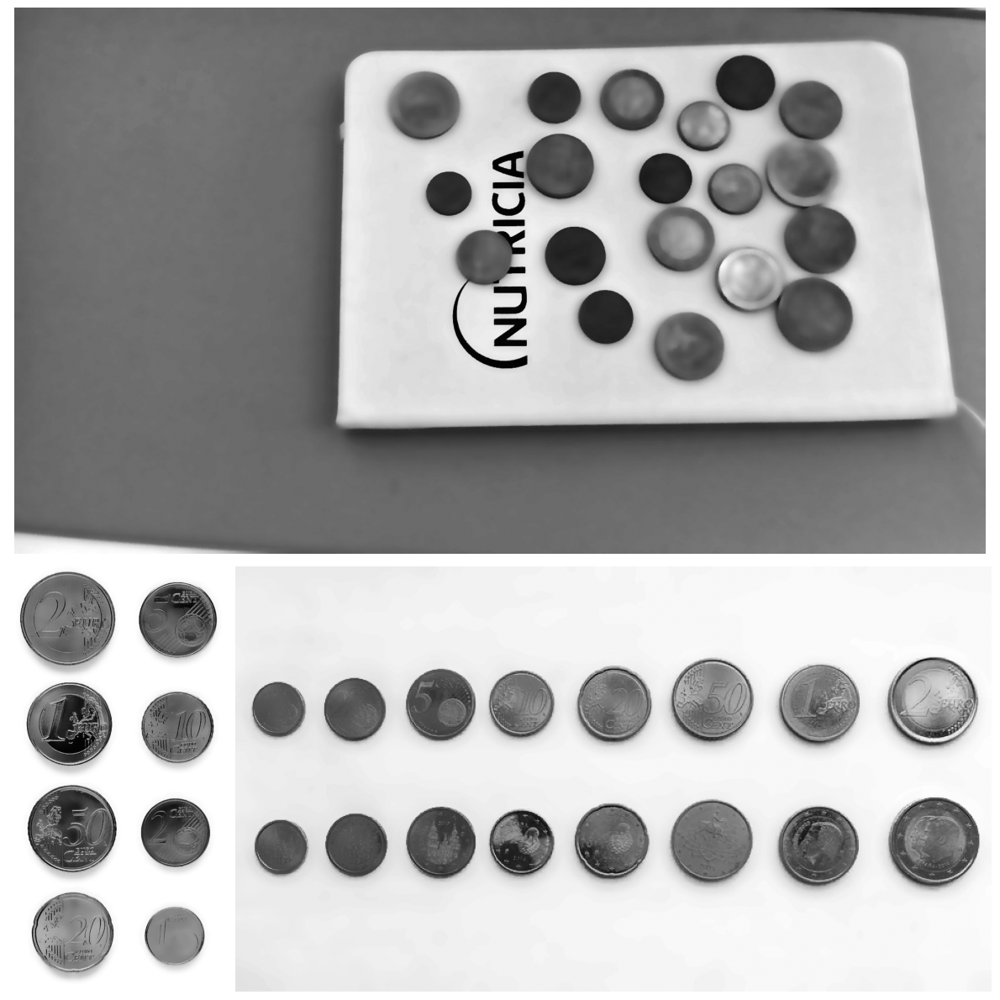

In [55]:
preprocessed = [pre_hough_transforms(img) for img in images]
show_each(preprocessed)

#### Transformada de Hough

Detección con `cv2.HOUGH_GRADIENT_ALT`, una variante de Hough más precisa en la que `param2` indica lo "perfecto" que debe ser el círculo (0,8 sobre 1). Se puede limitar el rango de radios buscados (aprovechado en el demostrador en vivo para ganar rapidez):

In [56]:
def hough_circles_detection(image, min_radius=0, max_radius=0, param1=200, param2=0.8):
    circles = cv2.HoughCircles(
        image,
        cv2.HOUGH_GRADIENT_ALT,
        dp=1,
        minDist=40,
        param1=param1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=max_radius
    )
    if circles is None:
        return np.empty((0, 3), dtype=np.int32)
    return np.around(circles)[0].astype(np.int32)

Todos los círculos que devuelve Hough sobre las imágenes de prueba, sin filtrar. Puede haber círculos repetidos sobre una misma moneda o círculos que no son monedas:

./exercises/monedas1.jpg: 22 círculos
./exercises/monedas2.jpg: 8 círculos
./exercises/monedas3.webp: 17 círculos


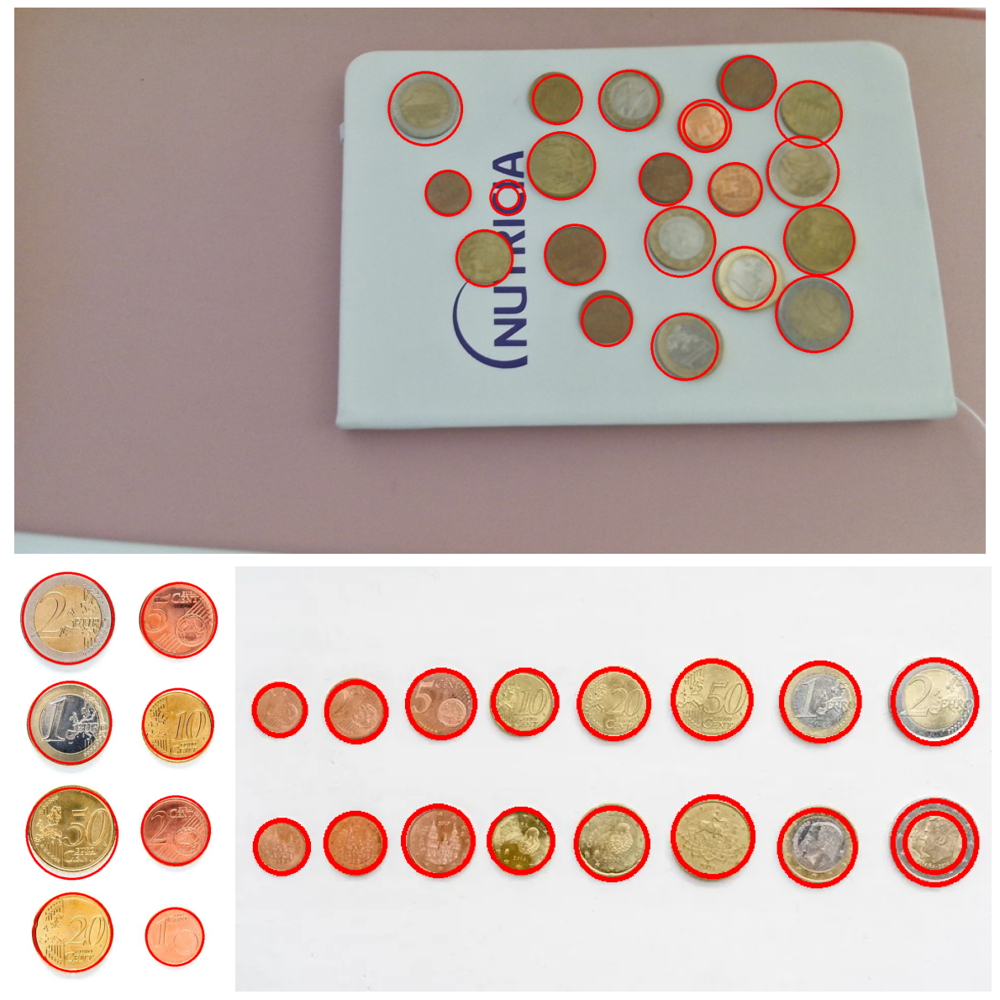

In [57]:
def draw_circles(img, circles, color):
    result = img.copy()
    for x, y, r in circles:
        cv2.circle(result, (int(x), int(y)), int(r), color, 4)
    return result

all_circles = [hough_circles_detection(p) for p in preprocessed]

for path, circles in zip(IMAGES, all_circles):
    print(f"{path}: {len(circles)} círculos")
show_each([draw_circles(img, circles, (255, 0, 0)) for img, circles in zip(images, all_circles)])

#### Filtrado de círculos

Puesto que Hough detecta más círculos (monedas repetidas y falsos positivos) es necesario realizar un filtrado de los círculos obtenidos. Un método es eliminar los círculos de radio demasiado grande:

In [58]:
def filter_big_radius(circles, factor=2, q=0.1):
    if len(circles) == 0:
        return circles
    return circles[circles[:, 2] <= factor * np.quantile(circles[:, 2], q)]

También es útil eliminar duplicados, si se detectan 2 círculos concéntricos o cuasi-concéntricos:

In [59]:
def remove_duplicates(circles):
    if len(circles) == 0:
        return []
    c = circles[np.argsort(-circles[:, 2])]
    dist = np.hypot(c[:, None, 0] - c[None, :, 0], c[:, None, 1] - c[None, :, 1])
    close = dist < 0.5 * np.minimum(c[:, None, 2], c[None, :, 2])

    keep, removed = [], np.zeros(len(c), dtype=bool)
    for i in range(len(c)):
        if not removed[i]:
            keep.append(i)
            removed |= close[i]
    return c[keep]

Resultado de los dos filtros sobre las imágenes de prueba. Los círculos restantes son las monedas candidatas:

./exercises/monedas1.jpg: 22 círculos -> 20 monedas candidatas
./exercises/monedas2.jpg: 8 círculos -> 8 monedas candidatas
./exercises/monedas3.webp: 17 círculos -> 16 monedas candidatas


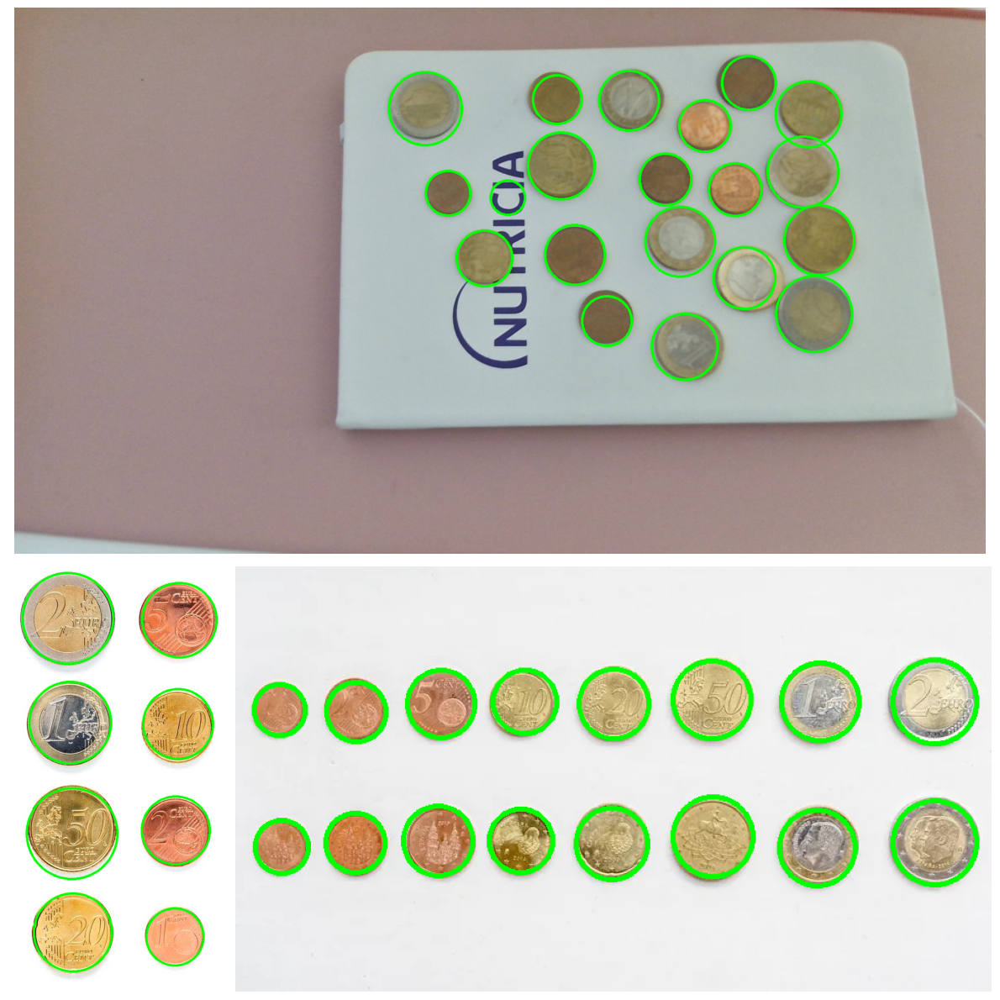

In [60]:
all_coins = [remove_duplicates(filter_big_radius(circles)) for circles in all_circles]

for path, circles, coins in zip(IMAGES, all_circles, all_coins):
    print(f"{path}: {len(circles)} círculos -> {len(coins)} monedas candidatas")
show_each([draw_circles(img, coins, (0, 255, 0)) for img, coins in zip(images, all_coins)])

### 1.4. Clasificación por color

Una vez identificadas las monedas, se pueden clasificar según su tipo. Para ello, el primer criterio discriminante es el color. Antes de eso, se recorta cada una de las monedas, aplicando una máscara circular para que solo queden los píxeles de la moneda, independizando la tarea de detección de cada una de ellas:

In [61]:
def cut(image, circle):
  x, y, r = circle
  radio = r + 2

  h, w = image.shape[:2] 

  y1 = max(0, y - radio)
  y2 = min(h, y + radio)
  x1 = max(0, x - radio)
  x2 = min(w, x + radio)

  roi = image[y1:y2, x1:x2]
  mask = np.zeros(roi.shape, dtype=roi.dtype)

  color_blanco = (255, 255, 255) if len(image.shape) == 3 else 255
  cv2.circle(mask, (x - x1, y - y1), r, color_blanco, -1)

  moneda = cv2.bitwise_and(roi, mask)

  return moneda

A continuación, para analizar el color, se utiliza el espacio de color **Lab**. El canal **a\*** mide el tono rojo y el canal **b\*** el tono amarillo. Para cada moneda (`coin_colors`) se calculan tres medianas:

- **a\*** de toda la moneda, para distinguir el cobre (más rojo) del oro.
- **b\*** del centro (45 % del radio) y del anillo exterior (entre el 78 % y el 98 % del radio), para detectar las monedas bimetálicas.

Una zona se considera amarilla si su b\* supera `SILVER_B = 142`; si no, se considera plateada.

El umbral de rojo no es fijo (`red_threshold`): entre las monedas de 1 solo color (céntimos), se aplica Otsu sobre sus valores de a\* para separar el cobre del oro según las condiciones de luz de cada imagen.

Por último, `color_probs` convierte estas medidas en una distribución de probabilidad con la función sigmoide y obtiene la probabilidad de que la moneda sea de cada metal. El resultado es un vector de 8 probabilidades, una por cada tipo de moneda. La probabilidad restante, no considerada en el vector (`1 - sum(vect)`) es la probabilidad de que ese círculo NO sea una moneda:

In [62]:
SILVER_B = 142

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def coin_colors(img_lab, circle):
    if img_lab is None or circle is None:
        return None
    moneda = cut(img_lab, circle)
    a, b = moneda[:, :, 1], moneda[:, :, 2]

    r = int(circle[2])
    centre_xy = (moneda.shape[1] // 2, moneda.shape[0] // 2)

    whole = np.zeros(moneda.shape[:2], dtype=np.uint8)
    cv2.circle(whole, centre_xy, int(r * 0.98), 255, -1)

    centre = np.zeros(moneda.shape[:2], dtype=np.uint8)
    cv2.circle(centre, centre_xy, int(r * 0.45), 255, -1)

    ring = np.zeros(moneda.shape[:2], dtype=np.uint8)
    cv2.circle(ring, centre_xy, int(r * 0.98), 255, -1)
    cv2.circle(ring, centre_xy, int(r * 0.78), 0, -1)

    return np.median(a[whole == 255]), np.median(b[centre == 255]), np.median(b[ring == 255])


def red_threshold(coins, default=138, min_gap=3):
    cents = [whole for whole, center, ring in coins
                   if center > SILVER_B and ring > SILVER_B]
    if len(cents) < 2:
        return default

    cents = np.array(cents, dtype=np.uint8)
    threshold, _ = cv2.threshold(cents, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    gold_cents, copper_cents = cents[cents <= threshold], cents[cents > threshold]
    if len(gold_cents) == 0 or len(copper_cents) == 0 or int(copper_cents.min()) - int(gold_cents.max()) < min_gap:
        return default

    return (int(gold_cents.max()) + int(copper_cents.min())) / 2


def color_probs(img_rgb, coins):
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    if img_lab is None:
        return None
    coin_features = [coin_colors(img_lab, c) for c in coins]
    if img_lab is None:
        return None
    a_threshold = red_threshold(coin_features)

    probs = []
    for a, b_center, b_ring in coin_features:
        yellow_in, yellow_ring = sigmoid((b_center - SILVER_B) / 2), sigmoid((b_ring - SILVER_B) / 2)
        red = sigmoid((a - a_threshold) / 2)
        per_metal = {"bronze": yellow_in * yellow_ring * red,
                     "gold": yellow_in * yellow_ring * (1 - red),
                     "1eur": (1 - yellow_in) * yellow_ring,
                     "2eur": yellow_in * (1 - yellow_ring)}
        probs.append(np.array([per_metal[m] / np.sum(METAL == m) for m in METAL]))
    return np.array(probs)

Metal de cada moneda en las imágenes de prueba. Cada moneda se etiqueta con su metal más probable, o con `?` si el color no es fiable (probabilidad total menor que 0,5):

./exercises/monedas1.jpg: umbral de rojo = 129.0, metales = {'bronze': 7, 'gold': 5, '1eur': 4, '2eur': 3, '?': 1}
./exercises/monedas2.jpg: umbral de rojo = 144.5, metales = {'bronze': 3, 'gold': 3, '1eur': 1, '2eur': 1}
./exercises/monedas3.webp: umbral de rojo = 137.5, metales = {'bronze': 6, 'gold': 6, '1eur': 2, '2eur': 2}


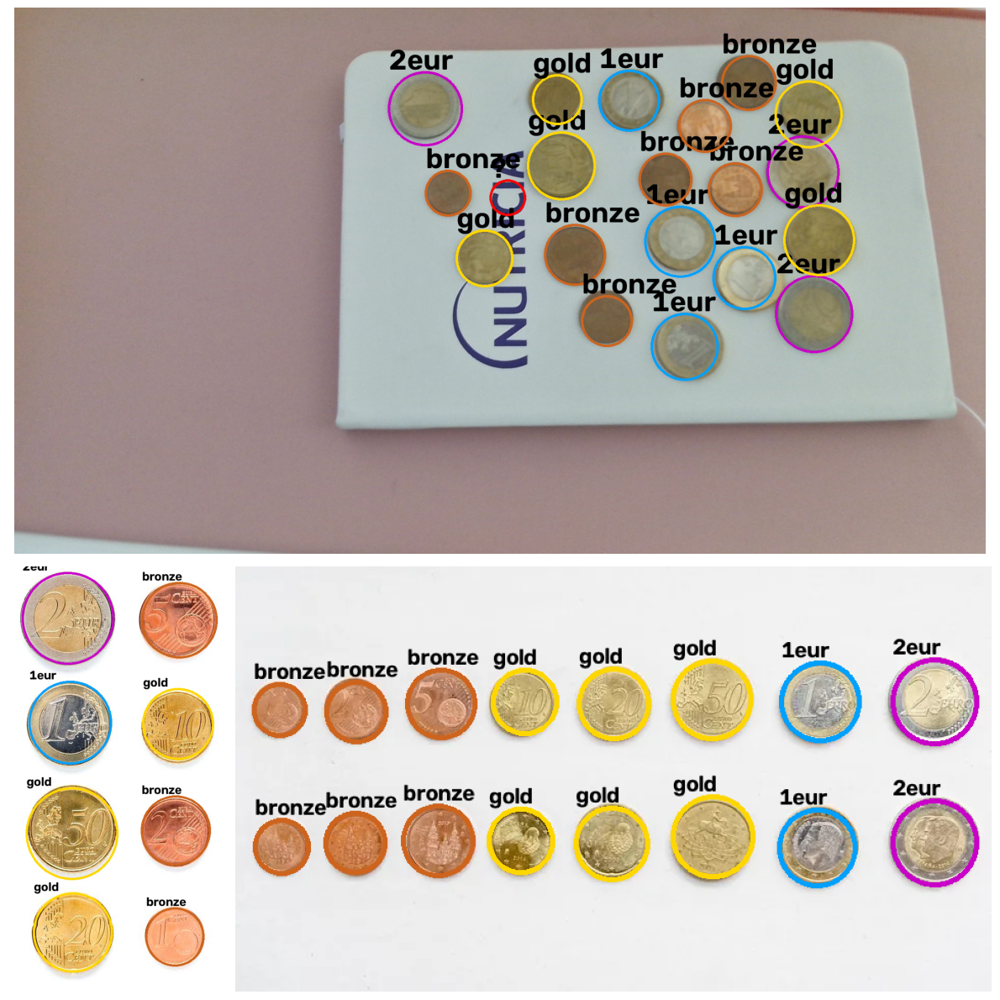

In [63]:
METAL_COLORS = {"bronze": (205, 100, 30), "gold": (255, 215, 0), "1eur": (0, 160, 255), "2eur": (200, 0, 200)}

def coin_metal(probs):
    return METAL[probs.argmax()] if probs.sum() >= 0.5 else None

def draw_metals(img, coins, probs):
    result = img.copy()
    scale = max(img.shape[:2]) / 1000
    for (x, y, r), p in zip(coins, probs):
        metal = coin_metal(p)
        cv2.circle(result, (int(x), int(y)), int(r), METAL_COLORS.get(metal, (255, 0, 0)), 4)
        put_text(result, metal or "?", (int(x - r), int(y - r - 5)), scale)
    return result


all_probs = [color_probs(img, coins) for img, coins in zip(images, all_coins)]

for path, img, coins, probs in zip(IMAGES, images, all_coins, all_probs):
    img_lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    threshold = red_threshold([coin_colors(img_lab, c) for c in coins])
    metals = [coin_metal(p) or "?" for p in probs]
    metal_counts = {m: metals.count(m) for m in METAL_COLORS if m in metals}
    if "?" in metals:
        metal_counts["?"] = metals.count("?")
    print(f"{path}: umbral de rojo = {threshold:.1f}, metales = {metal_counts}")
show_each([draw_metals(img, coins, probs) for img, coins, probs in zip(images, all_coins, all_probs)])

### 1.5. Clasificación por tamaño

El color solo indica el metal de cada moneda; dentro de cada metal, las monedas se distinguen por su diámetro.

Hough mide el radio en píxeles, así que primero hay que conocer la escala de la imagen (píxeles por milímetro). `find_px_per_mm` la calcula automáticamente: elige la escala que mejor encaja con las monedas presentes en la imagen. Después, `classify_coin` clasifica a cada moneda, en base a su metal y a su diámetro:

In [64]:
def closest_coin(radius_px, metal, px_per_mm):
    errors = np.abs(2 * radius_px / px_per_mm - COIN_DIAMETERS_MM) / COIN_DIAMETERS_MM
    errors[METAL != metal] = 9999999
    best = errors.argmin()
    return best, errors[best]


def total_error(scale, real_coins):
    return sum(closest_coin(coin[0], coin[1], scale)[1] for coin in real_coins)


def find_px_per_mm(coins, colors):
    real_coins = [(int(coins[i][2]), METAL[colors[i].argmax()])
                  for i in range(len(coins)) if colors[i].sum() >= 0.5]
    if real_coins is None:
        return None

    scales = []
    for radius, metal in real_coins:
        for diameter in COIN_DIAMETERS_MM[METAL == metal]:
            scales.append(2 * radius / diameter)

    total_errors = [total_error(scale, real_coins) for scale in scales]

    return scales[np.argmin(total_errors)] if total_errors else None


def classify_coin(radius_px, colors, px_per_mm):
    if colors.sum() < 0.5:
        return None
    best, error = closest_coin(radius_px, METAL[colors.argmax()], px_per_mm)
    if error > 0.12:
        return None
    return best

Escala calculada para cada imagen de prueba:

In [65]:
all_px_per_mm = [find_px_per_mm(coins, probs) for coins, probs in zip(all_coins, all_probs)]

for path, px_per_mm in zip(IMAGES, all_px_per_mm):
    print(f"{path}: {px_per_mm:.2f} px/mm")

./exercises/monedas1.jpg: 5.44 px/mm
./exercises/monedas2.jpg: 7.77 px/mm
./exercises/monedas3.webp: 3.15 px/mm


Clasificación final y suma del dinero. Las monedas descartadas (color dudoso o diámetro con más de un 12 % de error) se marcan con `?` en rojo:

./exercises/monedas1.jpg: {'1cent': 1, '2cent': 5, '5cent': 1, '10cent': 2, '50cent': 3, '1eur': 4, '2eur': 3, 'descartadas': 1, 'total (EUR)': 11.86}
./exercises/monedas2.jpg: {'1cent': 1, '2cent': 1, '5cent': 1, '10cent': 1, '20cent': 1, '50cent': 1, '1eur': 1, '2eur': 1, 'descartadas': 0, 'total (EUR)': 3.88}
./exercises/monedas3.webp: {'1cent': 2, '2cent': 2, '5cent': 2, '10cent': 2, '20cent': 2, '50cent': 2, '1eur': 2, '2eur': 2, 'descartadas': 0, 'total (EUR)': 7.76}


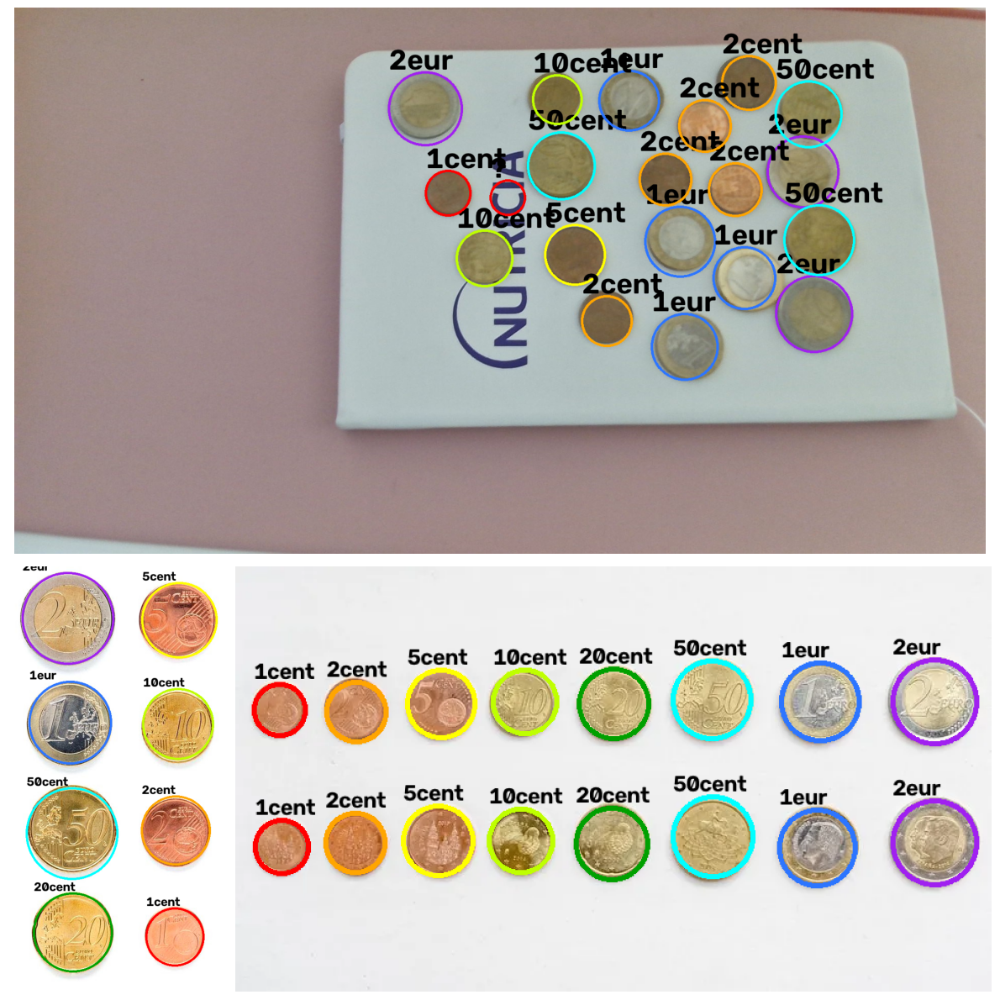

In [66]:
def draw_classification(img, coins, kinds):
    result = img.copy()
    scale = max(img.shape[:2]) / 1000
    for (x, y, r), kind in zip(coins, kinds):
        color = (255, 0, 0) if kind is None else COINS["color"][kind][::-1].tolist()
        cv2.circle(result, (int(x), int(y)), int(r), color, 4)
        put_text(result, "?" if kind is None else COINS["name"][kind], (int(x - r), int(y - r - 5)), scale)
    return result


results = []
for path, img, coins, probs, px_per_mm in zip(IMAGES, images, all_coins, all_probs, all_px_per_mm):
    kinds = [classify_coin(int(c[2]), p, px_per_mm) for c, p in zip(coins, probs)]
    counts = np.bincount(np.array([k for k in kinds if k is not None], dtype=int), minlength=len(COINS["name"]))

    summary = {str(name): int(count) for name, count in zip(COINS["name"], counts) if count}
    summary["descartadas"] = kinds.count(None)
    summary["total (EUR)"] = round(float(counts @ COINS["value"]), 2)
    print(f"{path}: {summary}")
    results.append(draw_classification(img, coins, kinds))

show_each(results)

La calibración funciona mejor si hay monedas de varios metales, sobre todo de 1 € o de 2 €, que solo tienen un diámetro posible. Si todas son del mismo metal, la escala puede ser ambigua y se pueden confundir monedas de ese metal.

### 1.6. Demostrador en vivo

#### Seguimiento entre fotogramas

En vídeo, las detecciones de un fotograma a otro varían. Para estabilizarlas, cada moneda se representa con un `Track`, que guarda su posición, radio, probabilidades de color y cuántas veces se ha detectado. `accuracy` indica la proporción de fotogramas en los que se ha detectado la moneda desde que apareció:

In [67]:
class Track:
    __slots__ = ("x", "y", "r", "probs", "kind", "hits", "misses", "total_misses", "seen")

    def __init__(self, x, y, r, probs):
        self.x = x
        self.y = y
        self.r = r
        self.probs = probs
        self.kind = None
        self.hits = 1
        self.misses = 0
        self.total_misses = 0
        self.seen = True

    @property
    def center(self):
        return int(self.x), int(self.y)

    @property
    def radius(self):
        return int(self.r)

    @property
    def accuracy(self):
        return self.hits / (self.hits + self.total_misses)

`update_tracks` actualiza los _tracks_ detectados con los valores del nuevo fotograma:

In [68]:
def update_tracks(tracks, coins, probs):
    for t in tracks:
        t.seen = False

    for coin, p in zip(coins, probs):
        best, best_d = None, None
        for t in tracks:
            if t.seen:
                continue
            d = np.hypot(coin[0] - t.x, coin[1] - t.y)
            if d < 0.5 * t.r and (best is None or d < best_d):
                best, best_d = t, d

        if best is None:
            tracks.append(Track(float(coin[0]), float(coin[1]), float(coin[2]), p.copy()))
        else:
            a = TRACK_ALPHA
            best.x += a * (coin[0] - best.x)
            best.y += a * (coin[1] - best.y)
            best.r += a * (coin[2] - best.r)
            best.probs = (1 - a) * best.probs + a * p
            best.hits += 1
            best.misses = 0
            best.seen = True

    for t in tracks:
        if not t.seen:
            t.misses += 1
            t.total_misses += 1
    return [t for t in tracks if t.misses <= MAX_MISSES]

`build_report` y `print_report` resumen, al terminar, las estadísticas de monedas y dinero obtenidas durante la demostración:

In [69]:
def build_report(tracks):
    counts = np.zeros(len(COINS["name"]), dtype=int)
    for t in tracks:
        if t.hits >= MIN_HITS and t.kind is not None:
            counts[t.kind] += 1
    return counts


def print_report(counts, max_total, min_total):
    for name, count in zip(COINS["name"], counts):
        if count:
            print(f"Moneda de {name}: {count}")
    print(f"Total: {counts @ COINS['value']:.2f} EUR")
    print(f"Máximo detectado: {max_total:.2f} EUR")
    print(f"Mínimo detectado: {min_total:.2f} EUR" if min_total is not None else "Mínimo detectado: -")

#### Bucle de captura

Constantes del demostrador (zona activa, rango de radios, búsqueda en fotogramas, seguimiento):

In [70]:
ACTIVE_ZONE = 0.8

MIN_COIN_RADIUS_MM = 8.125
MAX_COIN_RADIUS_MM = 12.875
FULL_SEARCH_EVERY = 60

MIN_HITS = 3
MAX_MISSES = 60
TRACK_ALPHA = 0.4

Zona activa: 80 % central de la imagen. Solo se cuentan las monedas que están completamente dentro, para evitar detecciones erróneas en los bordes:

In [71]:
def active_zone(frame):
    h, w = frame.shape[:2]
    return (w * (1 - ACTIVE_ZONE) / 2, h * (1 - ACTIVE_ZONE) / 2,
            w * (1 + ACTIVE_ZONE) / 2, h * (1 + ACTIVE_ZONE) / 2)


def inside_zone(circles, zone):
    x_min, y_min, x_max, y_max = zone
    x, y, r = circles[:, 0], circles[:, 1], circles[:, 2]
    return circles[(x - r >= x_min) & (x + r <= x_max) & (y - r >= y_min) & (y + r <= y_max)]

Detección de las monedas de un fotograma. Una vez calibrada la escala, Hough solo busca radios dentro del tamaño de las monedas (con un margen del 15 %). Cada `FULL_SEARCH_EVERY` fotogramas se busca sin límite, por si la cámara se ha acercado o alejado:

In [72]:
def radius_range(px_per_mm, frame_count):
    if px_per_mm is None or frame_count % FULL_SEARCH_EVERY == 0:
        return 0, 0
    return int(0.85 * MIN_COIN_RADIUS_MM * px_per_mm), int(1.15 * MAX_COIN_RADIUS_MM * px_per_mm)


def detect_coins(frame_rgb, zone, px_per_mm, frame_count):
    min_radius, max_radius = radius_range(px_per_mm, frame_count)
    circles = hough_circles_detection(to_gray(frame_rgb), min_radius, max_radius)
    return remove_duplicates(inside_zone(filter_big_radius(circles), zone))

Clasificación de los _tracks_ confirmados (`MIN_HITS` detecciones o más), a partir de los cuales se recalcula la escala:

In [73]:
def classify_tracks(tracks):
    confirmed = [t for t in tracks if t.hits >= MIN_HITS]
    px_per_mm = find_px_per_mm([np.array([t.x, t.y, t.r]) for t in confirmed], [t.probs for t in confirmed])
    for t in confirmed:
        t.kind = classify_coin(t.r, t.probs, px_per_mm) if px_per_mm is not None else None
    return [t for t in confirmed if t.kind is not None], px_per_mm

Dibujo sobre el fotograma (círculo, nombre y porcentaje de detección, zona activa, total):

In [74]:
def draw_frame(frame, coins, zone, total):
    for t in coins:
        cx, cy = t.center
        cv2.circle(frame, t.center, t.radius, COINS["color"][t.kind].tolist(), 3)
        put_text(frame, f"{COINS['name'][t.kind]} {t.accuracy:.0%}", (cx - t.radius, cy - t.radius - 6), 0.5)

    x_min, y_min, x_max, y_max = map(int, zone)
    cv2.rectangle(frame, (x_min, y_min), (x_max, y_max), (255, 255, 0), 1)
    put_text(frame, f"Total: {total:.2f} EUR", (10, 55), 0.8)

Bucle principal (detección y clasificación de monedas en cada fotograma). Al pulsar `Esc`, se termina el bucle y se imprime el resumen final:

In [75]:
video_capture = cv2.VideoCapture(0)
tracks = []
max_total, min_total = 0, None
px_per_mm = None
frame_count = 0
while True:
    ret, frame = video_capture.read()
    if ret:
        frame_count += 1
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        zone = active_zone(frame)

        coins = detect_coins(frame_rgb, zone, px_per_mm, frame_count)
        tracks = update_tracks(tracks, coins, color_probs(frame_rgb, coins))
        classified, px_per_mm = classify_tracks(tracks)

        total = sum(COINS["value"][t.kind] for t in classified)
        max_total = max(max_total, total)
        if total > 0:
            min_total = total if min_total is None else min(min_total, total)

        draw_frame(frame, classified, zone, total)
        cv2.imshow("Contador de monedas", frame)
    if cv2.waitKey(20) == 27:
        break

video_capture.release()
cv2.destroyAllWindows()

print_report(build_report(tracks), max_total, min_total)

Total: 0.00 EUR
Máximo detectado: 0.00 EUR
Mínimo detectado: -


## Tarea 2: Clasificación de microplásticos

Clasificar las partículas de una imagen de microplásticos en fragmentos, pellets y alquitrán a partir de características geométricas y de apariencia, sin usar aprendizaje profundo, y evaluar el resultado con métricas y una matriz de confusión.

### 2.1. Planteamiento

Clasificación de las partículas de `MPs_test.jpg` en fragmentos (FRA), pellets (PEL) y alquitrán (TAR) a partir de las tres fotos de entrenamiento, sin aprendizaje profundo. Las decisiones del _pipeline_ se justifican en [`ablations_plastics.ipynb`](./ablations_plastics.ipynb).

### 2.2. Configuración

Constantes y configuración base del _pipeline_. Se fija la semilla aleatoria (`np.random.seed(0)`) para que el _data augmentation_ sea reproducible:

In [76]:
import csv
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

TRAIN = {"FRA": "exercises/plastics/fragment-03-olympus-10-01-2020.JPG",
         "PEL": "exercises/plastics/pellet-03-olympus-10-01-2020.JPG",
         "TAR": "exercises/plastics/tar-03-olympus-10-01-2020.JPG"}
TEST_IMAGE = "exercises/plastics/MPs_test.jpg"
TEST_ANNOTATIONS = "exercises/plastics/MPs_test_bbs.csv"

SCALE_TRAIN = 0.25
BG_KSIZE = 101
COLOR_THRESHOLD = 10
MIN_AREA, MAX_AREA = 40, 8000
BORDER_MARGIN = 0.02
N_AUG = 5

np.random.seed(0)

### 2.3. Segmentación

Detección de las partículas a partir de la distancia de color (en Lab) de cada píxel a su fondo:

In [77]:
def compute_background(img):
    return cv2.merge([cv2.medianBlur(channel, BG_KSIZE) for channel in cv2.split(img)])

def color_distance(img, bg):
    return np.sqrt(((img.astype(np.float32) - bg.astype(np.float32)) ** 2).sum(axis=-1))

def is_valid_particle(contour, shape):
    area = cv2.contourArea(contour)
    if not (MIN_AREA <= area <= MAX_AREA) or len(contour) < 5:
        return False

    margin = int(BORDER_MARGIN * max(shape))
    x, y, w, h = cv2.boundingRect(contour)
    return x > margin and y > margin and \
           x + w < shape[1] - margin and y + h < shape[0] - margin

def segment(img):
    lab = cv2.cvtColor(cv2.bilateralFilter(img, 7, 40, 7), cv2.COLOR_BGR2LAB)
    bg = compute_background(lab)

    _, mask = cv2.threshold(color_distance(lab, bg), COLOR_THRESHOLD, 255, cv2.THRESH_BINARY)
    mask = cv2.medianBlur(mask.astype(np.uint8), 3)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    particles = [c for c in contours if is_valid_particle(c, mask.shape)]
    return particles, lab, bg

Comprobación de la segmentación en las fotos de entrenamiento:

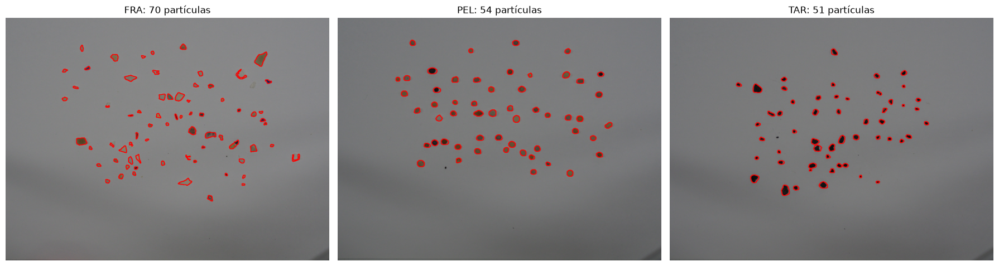

In [78]:
plt.figure(figsize=(18, 5))
for i, (label, path) in enumerate(TRAIN.items()):
    img = cv2.resize(cv2.imread(path), None, fx=SCALE_TRAIN, fy=SCALE_TRAIN, interpolation=cv2.INTER_AREA)
    particles, _, _ = segment(img)
    vis = img.copy()
    cv2.drawContours(vis, particles, -1, (0, 0, 255), 2)
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.title(f"{label}: {len(particles)} partículas")
    plt.axis("off")
plt.tight_layout()
plt.show()

### 2.4. Características

Generación de las características de cada partícula: circularidad, y brillo y color relativos al fondo:

In [79]:
def shape_features(contour):
    x, y, w, h = cv2.boundingRect(contour)
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    return {
        "x": x, "y": y, "w": w, "h": h,
        "area": area,
        "perimeter": perimeter,
        "circularity": 4 * np.pi * area / perimeter ** 2,
    }

def color_features(contour, img_lab, bg):
    mask = np.zeros(img_lab.shape[:2], np.uint8)
    cv2.drawContours(mask, [contour], -1, 255, -1)

    particle = img_lab[mask > 0].astype(np.float32)
    background = bg[mask > 0].astype(np.float32)

    L_ratio = particle[:, 0].mean() / background[:, 0].mean()
    chroma_rel = color_distance(particle[:, 1:], background[:, 1:]).mean()

    return {"L_ratio": L_ratio, "chroma_rel": chroma_rel}

Combinación de las características de todas las partículas de una imagen en un único _dataframe_:

In [80]:
def extract_particles(img):
    contours, img_lab, bg = segment(img)
    rows = [{**shape_features(c), **color_features(c, img_lab, bg)} for c in contours]
    df = pd.DataFrame(rows)
    return df, contours

### 2.5. _Data augmentation_

Generación de versiones de cada foto con otra iluminación, color, nitidez y ruido:

In [81]:
DATA_AUGMENTATION = {
    "contrast":   (0.8, 1.2),
    "brightness": (-20, 20),
    "color_gain": (0.9, 1.1),
    "gamma":      (0.8, 1.25),
    "blur":       (0.01, 1.2),
    "noise":      (0, 4),
}

def rand(name, size=None):
    return np.random.uniform(DATA_AUGMENTATION[name][0], DATA_AUGMENTATION[name][1], size)

def augment(img):
    img = img.astype(np.float32)

    img = cv2.GaussianBlur(img, (0, 0), rand("blur"))
    img = img + np.random.normal(0, rand("noise"), img.shape)
    img = img * rand("contrast") + rand("brightness")
    img = img * rand("color_gain", 3)
    img = 255 * (np.clip(img, 0, 255) / 255) ** rand("gamma")

    return img.astype(np.uint8)

Ejemplos: foto original y tres versiones aumentadas de cada clase:

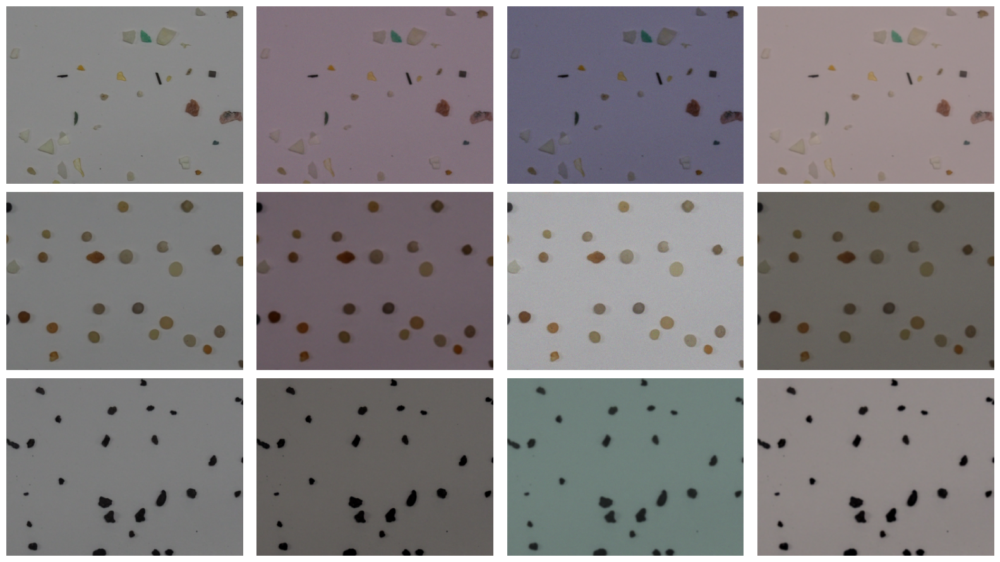

In [82]:
crops = []
for label in TRAIN:
    img = cv2.resize(cv2.imread(TRAIN[label]), None, fx=SCALE_TRAIN, fy=SCALE_TRAIN, interpolation=cv2.INTER_AREA)
    crop = img[230:530, 350:750]
    crops += [crop] + [augment(crop) for _ in range(3)]

plt.figure(figsize=(16, 9))
for i, c in enumerate(crops):
    plt.subplot(3, 4, i + 1)
    plt.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
    plt.axis("off")
plt.tight_layout()
plt.show()

### 2.6. Clasificador por reglas heurísticas

TAR si es oscuro y sin tonalidad, PEL si es redondo y FRA en otro caso. Los umbrales se eligen con una búsqueda en rejilla: se prueban todas sus combinaciones y se elige la que obtiene el mayor acierto equilibrado en las fotos de entrenamiento:

In [83]:
THRESHOLD_POSSIBILITIES = {
    "max_brightness": np.arange(0.30, 0.96, 0.05),
    "max_color": np.arange(2, 16, 1.0),
    "min_circularity": np.arange(0.70, 0.93, 0.01),
}

def predict(df, t):
    is_tar = (df["L_ratio"] < t["max_brightness"]) & (df["chroma_rel"] < t["max_color"])
    is_pel = df["circularity"] > t["min_circularity"]
    return np.select([is_tar, is_pel], ["TAR", "PEL"], default="FRA")

def all_threshold_combinations():
    return [{"max_brightness": b, "max_color": c, "min_circularity": r}
             for b in THRESHOLD_POSSIBILITIES["max_brightness"]
             for c in THRESHOLD_POSSIBILITIES["max_color"]
             for r in THRESHOLD_POSSIBILITIES["min_circularity"]]

def fit(df):
    all_thresholds = all_threshold_combinations()
    scores = [balanced_accuracy_score(df["label"], predict(df, t)) for t in all_thresholds]
    best = np.argmax(scores)
    return all_thresholds[best], scores[best]

### 2.7. Entrenamiento

Extracción de las partículas de las fotos de entrenamiento (originales y aumentadas), etiquetadas con la clase de su foto, y búsqueda de los umbrales:

In [84]:
def load_training_image(path):
    return cv2.resize(cv2.imread(path), None, fx=SCALE_TRAIN, fy=SCALE_TRAIN, interpolation=cv2.INTER_AREA)


rows = []
for label, path in TRAIN.items():
    img = load_training_image(path)
    for version in [img] + [augment(img) for _ in range(N_AUG)]:
        df, _ = extract_particles(version)
        df["label"] = label
        rows.append(df)

train = pd.concat(rows, ignore_index=True)
thresholds, train_score = fit(train)

Resultado del entrenamiento: partículas por clase y umbrales elegidos:

In [85]:
print(train["label"].value_counts().to_dict())

print("Umbrales:", {k: round(float(v), 2) for k, v in thresholds.items()})
print("Acierto equilibrado en entrenamiento:", round(train_score, 3))

{'FRA': 420, 'PEL': 327, 'TAR': 307}
Umbrales: {'max_brightness': 0.6, 'max_color': 6.0, 'min_circularity': 0.83}
Acierto equilibrado en entrenamiento: 0.838


### 2.8. Evaluación en la imagen de test

Emparejamiento de cada partícula anotada con la detección que más se solapa con ella (IoU ≥ 0,3):

In [86]:
def iou(a, b):
    inter_w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    inter_h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    intersection = inter_w * inter_h
    union = (a[2] - a[0]) * (a[3] - a[1]) + \
            (b[2] - b[0]) * (b[3] - b[1]) - intersection
    return intersection / union


def match(df, annotations, min_iou=0.3):
    detections = list(zip(df.x, df.y, df.x + df.w, df.y + df.h))
    matched = {}

    for ann in annotations:
        box = (int(ann["x_min"]), int(ann["y_min"]), int(ann["x_max"]), int(ann["y_max"]))
        free = [i for i in range(len(detections)) if i not in matched]
        if not free:
            break
        best = max(free, key=lambda i: iou(box, detections[i]))
        if iou(box, detections[best]) >= min_iou:
            matched[best] = ann["label"]

    out = df.loc[list(matched)].copy()
    out["label"] = list(matched.values())
    return out

Métricas y matriz de confusión:

In [87]:
def evaluate(y, y_pred, title=""):
    print(f"Accuracy  = {accuracy_score(y, y_pred):.3f}")
    print(f"Precision = {precision_score(y, y_pred, average='weighted', zero_division=0):.3f}")
    print(f"Recall    = {recall_score(y, y_pred, average='weighted', zero_division=0):.3f}")
    print(f"F1 Score  = {f1_score(y, y_pred, average='weighted', zero_division=0):.3f}")

    conf_matrix = confusion_matrix(y, y_pred, labels=list(TRAIN))
    plt.figure(figsize=(6, 6))
    ax = sns.heatmap(conf_matrix, annot=True, fmt="d", cbar=False, cmap="Blues",
                     xticklabels=list(TRAIN), yticklabels=list(TRAIN), annot_kws={"size": 16})
    ax.set_xlabel("Predicha")
    ax.set_ylabel("Real/Anotado")
    ax.set_title(title)
    plt.show()
    return conf_matrix

Resumen de las detecciones y dibujo del resultado sobre la imagen de _test_:

In [88]:
def load_annotations(path):
    with open(path, newline="") as file:
        return list(csv.DictReader(file))

def detection_summary(test, matched, annotations):
    return {"anotadas": len(annotations),
            "detectadas": len(test),
            "emparejadas": len(matched),
            "no detectadas": len(annotations) - len(matched),
            "falsos positivos": len(test) - len(matched),
            "correctas": int((matched["label"] == matched["pred"]).sum())}

def contour_color(i, matched):
    if i not in matched.index:
        return (255, 0, 0)
    if matched.at[i, "label"] == matched.at[i, "pred"]:
        return (0, 255, 0)
    return (0, 0, 255)

def draw_test(img, contours, matched):
    vis = img.copy()
    for i, c in enumerate(contours):
        cv2.drawContours(vis, [c], -1, contour_color(i, matched), 2)
    return cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)

def show_test(img, contours, matched):
    plt.figure(figsize=(8, 12))
    plt.imshow(draw_test(img, contours, matched))
    plt.axis("off")
    plt.title("Verde: acierto - Rojo: fallo - Azul: falso positivo")
    plt.show()

Clasificación de la imagen de _test_:

{'anotadas': 120, 'detectadas': 108, 'emparejadas': 103, 'no detectadas': 17, 'falsos positivos': 5, 'correctas': 83}
Accuracy  = 0.806
Precision = 0.821
Recall    = 0.806
F1 Score  = 0.804


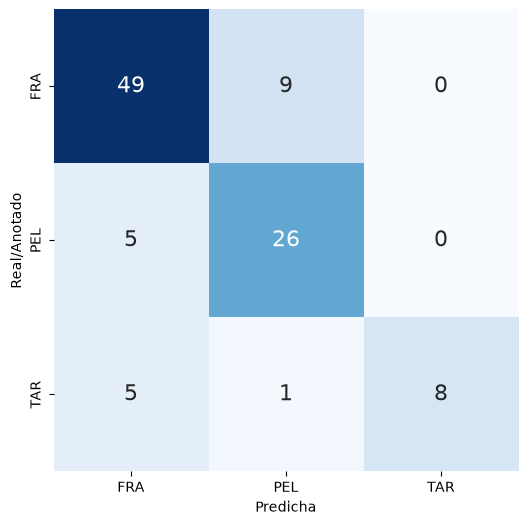

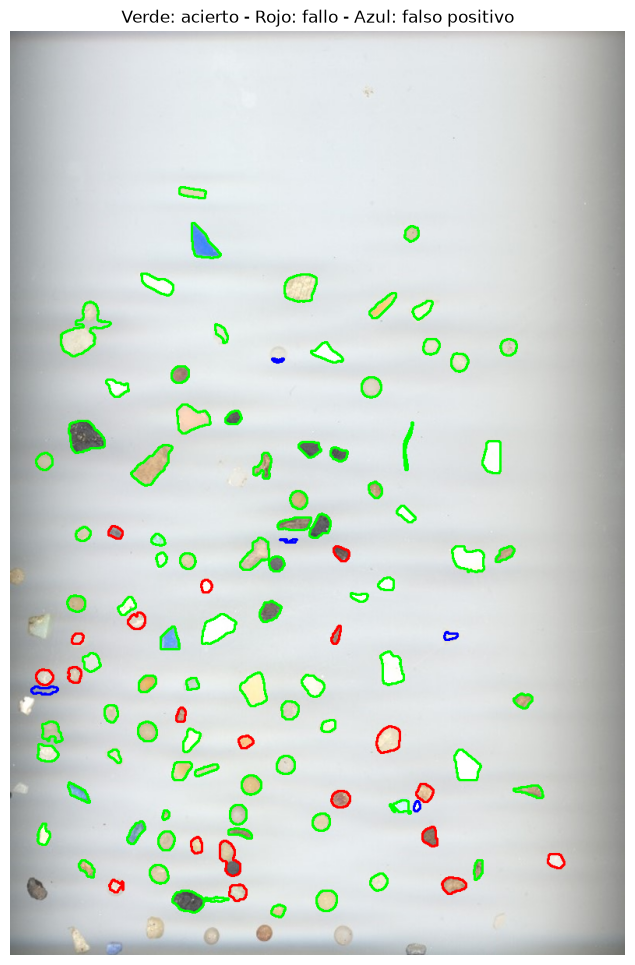

In [89]:
test_img = cv2.imread(TEST_IMAGE)
test, test_contours = extract_particles(test_img)
annotations = load_annotations(TEST_ANNOTATIONS)

matched = match(test, annotations)
matched["pred"] = predict(matched, thresholds)
y, y_pred = matched["label"].values, matched["pred"].values

print(detection_summary(test, matched, annotations))
evaluate(y, y_pred)
show_test(test_img, test_contours, matched)

### 2.9. Comparación con otros clasificadores

Como tarea adicional, se ha decidido comparar el rendimiento de las heurísticas propias frente a distintos clasificadores (k-NN, árbol de decisión, SVM y Random Forest). Se han mantenido las características y las imágenes de entrenamiento y de _test_:

In [90]:
FEATURES = ["circularity", "L_ratio", "chroma_rel"]
MODELS = {
    "k-NN (k=5)":      make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Árbol (prof. 3)": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0),
    "SVM (RBF)":       make_pipeline(StandardScaler(), SVC(class_weight="balanced")),
    "Random Forest":   RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0),
}

results = [{"modelo": "Reglas heurísticas",
            "balanced (train)": train_score,
            "accuracy": accuracy_score(y, y_pred),
            "balanced": balanced_accuracy_score(y, y_pred),
            "f1": f1_score(y, y_pred, average="weighted"),
            "correctas/120": int((y == y_pred).sum())}]

for name, model in MODELS.items():
    model.fit(train[FEATURES], train["label"])
    pred = model.predict(matched[FEATURES])
    results.append({"modelo": name,
                    "balanced (train)": balanced_accuracy_score(train["label"], model.predict(train[FEATURES])),
                    "accuracy": accuracy_score(y, pred),
                    "balanced": balanced_accuracy_score(y, pred),
                    "f1": f1_score(y, pred, average="weighted"),
                    "correctas/120": int((y == pred).sum())})

pd.DataFrame(results).round(3)

,modelo,balanced (train),accuracy,balanced,f1,correctas/120
0,Reglas heurísticas,0.838,0.806,0.752,0.804,83
1,k-NN (k=5),0.917,0.660,0.550,0.584,68
2,Árbol (prof. 3),0.885,0.641,0.498,0.549,66
3,SVM (RBF),0.902,0.650,0.522,0.565,67
4,Random Forest,1.000,0.641,0.498,0.549,66


Las reglas obtienen el mejor resultado en la imagen de _test_, aunque son las que peor puntúan en el entrenamiento (columna `balanced (train)` frente a `balanced`). Los clasificadores entrenados llegan a 0,88–1,00 en entrenamiento, pero bajan a 0,50–0,55 en el _test_.

Se estima que la causa es el cambio de dispositivo: en el escáner, todas las partículas se ven más claras y con más color que en las fotos de cámara. Los clasificadores entrenados aprenden reglas más complejas que podrían dejar de cumplirse al cambiar de dispositivo. Las reglas, en cambio, al ser más sencillas, solo usan lo más "evidente" y que, por tanto, se mantiene en cámara y en escáner.